In [7]:
import os
import pandas as pd
import kagglehub
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Download and load the dataset
path = kagglehub.dataset_download("miadul/customer-churn-prediction-business-dataset")
csv_path = os.path.join(path, "customer_churn_business_dataset.csv")

df = pd.read_csv(csv_path)

# 2. Basic dataset dimensions and preview
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
df.head()

Dataset Shape: 10000 rows, 32 columns



,customer_id,gender,age,country,city,customer_segment,tenure_months,signup_channel,contract_type,monthly_logins,...,avg_resolution_time,complaint_type,csat_score,escalations,email_open_rate,marketing_click_rate,nps_score,survey_response,referral_count,churn
0,CUST_00001,Male,68,Bangladesh,London,SME,22,Web,Monthly,26,...,13.354360,Service,4.0,0,0.71,0.40,27,Satisfied,1,0
1,CUST_00002,Female,57,Canada,Sydney,Individual,9,Mobile,Monthly,7,...,25.140088,Billing,2.0,0,0.78,0.33,-19,Neutral,2,1
2,CUST_00003,Male,24,Germany,New York,SME,58,Web,Yearly,19,...,27.572928,Service,3.0,0,0.35,0.49,80,Neutral,1,0
3,CUST_00004,Male,49,Australia,Dhaka,Individual,19,Mobile,Yearly,34,...,26.420822,Technical,5.0,1,0.83,0.15,100,Neutral,0,0
4,CUST_00005,Male,65,Bangladesh,Delhi,Individual,52,Web,Monthly,20,...,26.674579,Technical,4.0,0,0.65,0.44,21,Unsatisfied,1,0


In [8]:
# 3. Data types and null checks
df.info()

# 4. Check target variable balance
print("\n--- Churn Distribution ---")
print(df['churn'].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 32 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             10000 non-null  str    
 1   gender                  10000 non-null  str    
 2   age                     10000 non-null  int64  
 3   country                 10000 non-null  str    
 4   city                    10000 non-null  str    
 5   customer_segment        10000 non-null  str    
 6   tenure_months           10000 non-null  int64  
 7   signup_channel          10000 non-null  str    
 8   contract_type           10000 non-null  str    
 9   monthly_logins          10000 non-null  int64  
 10  weekly_active_days      10000 non-null  int64  
 11  avg_session_time        10000 non-null  float64
 12  features_used           10000 non-null  int64  
 13  usage_growth_rate       10000 non-null  float64
 14  last_login_days_ago     10000 non-null  int64  
 1

In [9]:
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.drop('churn')

churn_comparison = df.groupby('churn')[num_cols].mean().T
churn_comparison.columns = ['Retained (0)', 'Churned (1)']
churn_comparison['Difference (%)'] = (
    (churn_comparison['Churned (1)'] - churn_comparison['Retained (0)'])
    / churn_comparison['Retained (0)'] * 100
).round(2)

# Sort by biggest behavioral differences
churn_comparison.sort_values(by='Difference (%)', ascending=False)

,Retained (0),Churned (1),Difference (%)
payment_failures,0.473995,0.738492,55.80
usage_growth_rate,0.019157,0.021763,13.60
last_login_days_ago,9.382114,10.587659,12.85
escalations,0.292349,0.309500,5.87
nps_score,19.071166,19.456415,2.02
email_open_rate,0.498711,0.507512,1.76
age,45.849872,46.400588,1.20
features_used,4.986747,5.026445,0.80
support_tickets,1.206482,1.207640,0.10
marketing_click_rate,0.253673,0.252713,-0.38


In [10]:
# 2. Linear correlations with the target
correlations = df[num_cols].apply(lambda col: col.corr(df['churn'])).sort_values()

print("--- Top Features Negatively Correlated with Churn (Higher = Less Churn) ---")
print(correlations.head(5).round(3))

print("\n--- Top Features Positively Correlated with Churn (Higher = More Churn) ---")
print(correlations.tail(5).round(3))

--- Top Features Negatively Correlated with Churn (Higher = Less Churn) ---
csat_score            -0.158
tenure_months         -0.117
monthly_logins        -0.098
total_revenue         -0.070
avg_resolution_time   -0.009
dtype: float64

--- Top Features Positively Correlated with Churn (Higher = More Churn) ---
escalations            0.010
age                    0.010
email_open_rate        0.012
last_login_days_ago    0.037
payment_failures       0.112
dtype: float64


In [11]:
# 3. Churn rate by categorical attributes
categorical_cols = [
    'customer_segment',
    'contract_type',
    'payment_method',
    'complaint_type',
    'survey_response',
    'price_increase_last_3m'
]

for col in categorical_cols:
    grouped = df.groupby(col, dropna=False)['churn'].agg(
        Total_Customers='count',
        Churn_Rate=lambda x: f"{x.mean() * 100:.2f}%"
    )
    print(f"\n--- Churn by {col} ---")
    print(grouped)


--- Churn by customer_segment ---
                  Total_Customers Churn_Rate
customer_segment                            
Enterprise                    987      9.42%
Individual                   5984      9.98%
SME                          3029     10.93%

--- Churn by contract_type ---
               Total_Customers Churn_Rate
contract_type                            
Monthly                   4967     10.33%
Quarterly                 3050      9.93%
Yearly                    1983     10.34%

--- Churn by payment_method ---
                Total_Customers Churn_Rate
payment_method                            
Bank Transfer              1488      9.88%
Card                       5955     10.39%
PayPal                     2557      9.97%

--- Churn by complaint_type ---
                Total_Customers Churn_Rate
complaint_type                            
Billing                    2427     10.18%
Service                    2030      9.95%
Technical                  3498     10.32%
Na

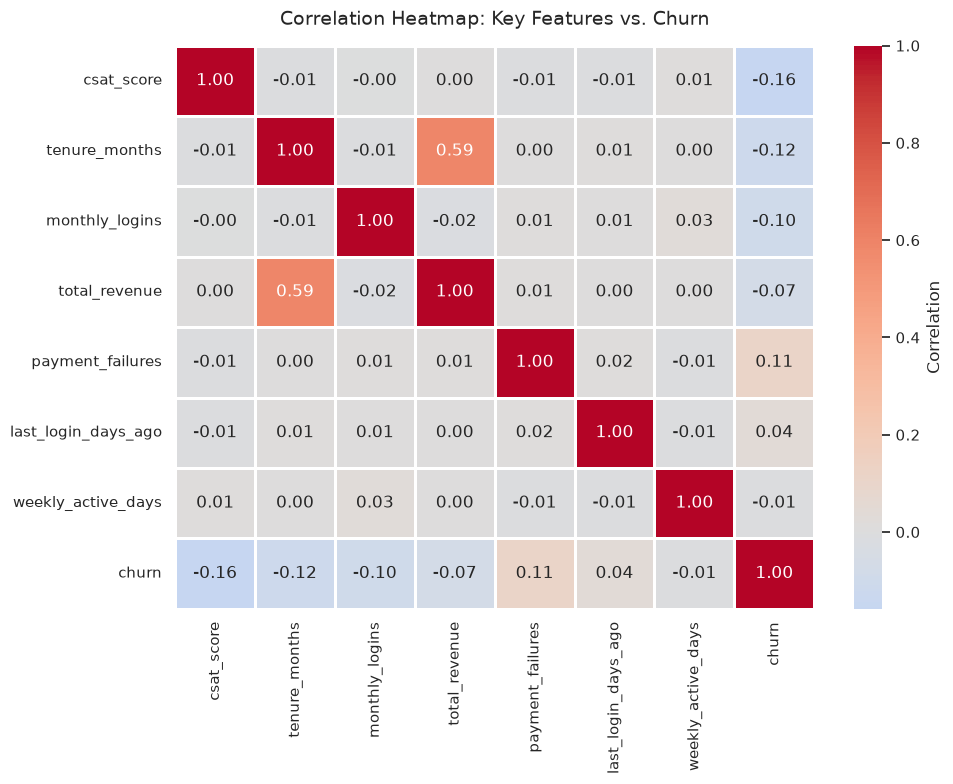

In [12]:
# Set visual style
sns.set_theme(style="whitegrid")

# Select key numerical features showing notable correlation with churn
key_features = [
    'csat_score', 'tenure_months', 'monthly_logins',
    'total_revenue', 'payment_failures', 'last_login_days_ago',
    'weekly_active_days', 'churn'
]

plt.figure(figsize=(10, 8))
corr_matrix = df[key_features].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    center=0,
    linewidths=0.8,
    cbar_kws={'label': 'Correlation'}
)

plt.title("Correlation Heatmap: Key Features vs. Churn", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

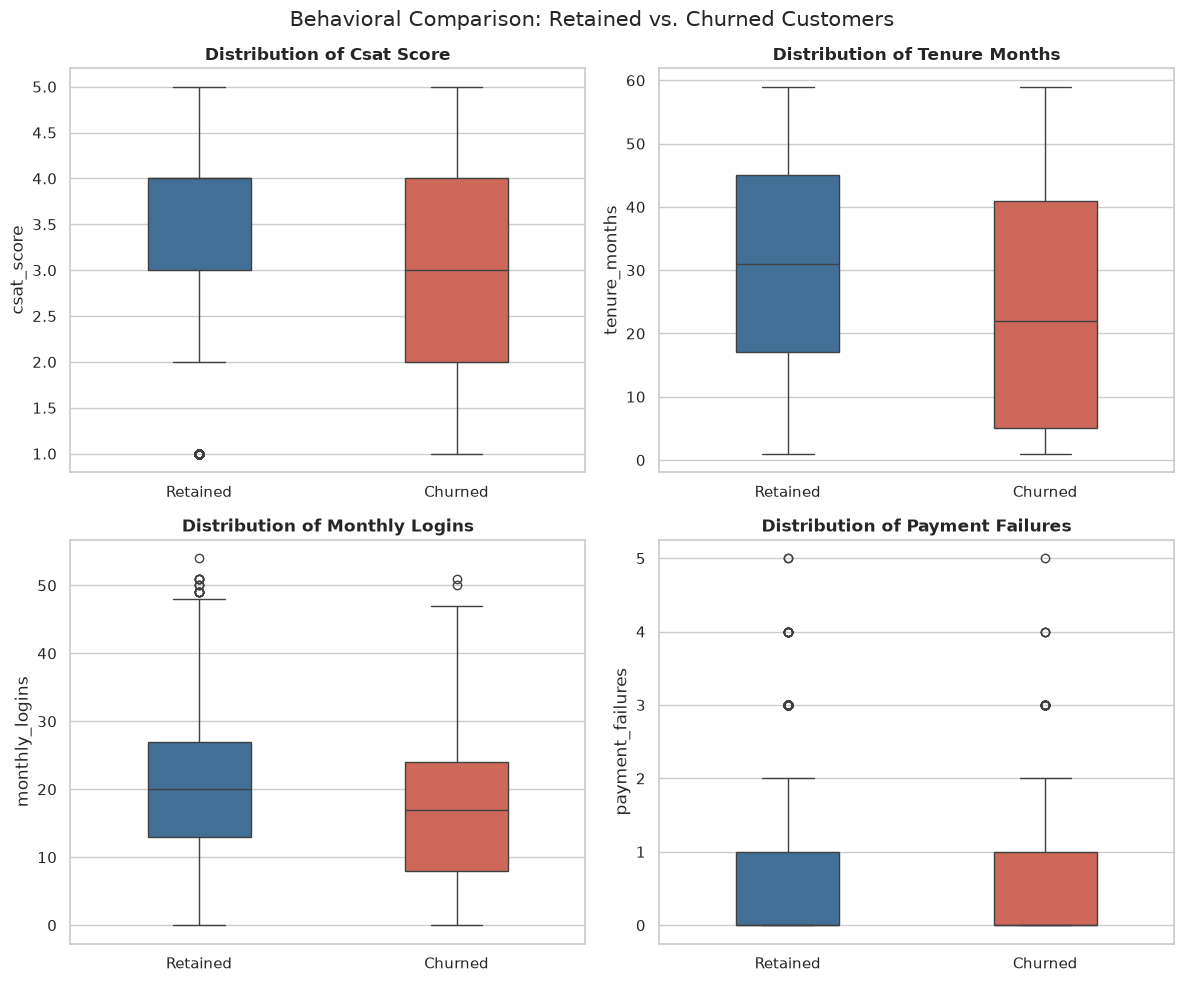

In [ ]:
# Top 4 features that separate churners from retained users
features_to_plot = ['csat_score', 'tenure_months', 'monthly_logins', 'payment_failures']

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

# Friendly label mapping for the chart
df_plot = df.copy()
df_plot['churn_label'] = df_plot['churn'].map({0: 'Retained', 1: 'Churned'})
palette = {'Retained': '#3470a3', 'Churned': '#e05a47'}

for i, col in enumerate(features_to_plot):
    sns.boxplot(
        x='churn_label',
        y=col,
        data=df_plot,
        ax=axes[i],
        palette=palette,
        hue='churn_label',
        legend=False,
        width=0.4
    )
    axes[i].set_title(f"Distribution of {col.replace('_', ' ').title()}", fontsize=12, fontweight='bold')
    axes[i].set_xlabel("")
    axes[i].set_ylabel(col)

plt.suptitle("Behavioral Comparison: Retained vs. Churned Customers", fontsize=15, y=0.98)
plt.tight_layout()
plt.show()

In [14]:
# --- STEP 3: DATA CLEANING & PREPROCESSING ---

# 1. Create a clean copy
df_clean = df.copy()

# 2. Drop unique identifier
df_clean = df_clean.drop(columns=['customer_id'])

# 3. Handle missing values: fill missing complaint types with 'No Complaint'
df_clean['complaint_type'] = df_clean['complaint_type'].fillna('No Complaint')

# 4. Separate features (X) and target label (y)
X = df_clean.drop(columns=['churn'])
y = df_clean['churn']

# 5. One-Hot Encode all categorical columns (drop_first avoids dummy variable trap)
X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)

# 6. Verification checks
print(f"Original features shape : {X.shape}")
print(f"Encoded features shape  : {X_encoded.shape}")
print(f"Total remaining nulls   : {X_encoded.isnull().sum().sum()}")
print(f"Target distribution     :\n{y.value_counts()}")

Original features shape : (10000, 30)
Encoded features shape  : (10000, 47)
Total remaining nulls   : 0
Target distribution     :
churn
0    8979
1    1021
Name: count, dtype: int64


### Why Use `StandardScaler` for Logistic Regression?

`StandardScaler` standardizes each feature using the **Z-score formula**:
$$z = \frac{x - \mu}{\sigma}$$
centering each column around a mean of **$\mu = 0$** with a standard deviation of **$\sigma = 1$**.

#### Why It Is Critical for Our Pipeline:
1. **Prevents Scale Dominance**: In our dataset, `total_revenue` ranges in the thousands (~$1,000s), while `csat_score` is 1 to 5 and `email_open_rate` is 0 to 1. Without scaling, larger magnitude numbers artificially dominate distance and gradient calculations.
2. **Fair Regularization in Logistic Regression**: Scikit-learn's `LogisticRegression` applies an $L_2$ penalty ($\lambda \sum w_i^2$) by default to prevent overfitting. Unscaled tiny-range features require huge weights to have an impact, which causes the penalty to unfairly crush them toward zero.
3. **Faster Optimization**: Equal scales allow gradient descent to converge smoothly toward the global minimum instead of oscillating across an elongated loss landscape.
4. **Preventing Data Leakage**: We run `fit_transform` **only on `X_train`** and `transform` on `X_test`. This ensures normalization parameters ($\mu, \sigma$) are learned strictly from historical training data, mimicking how unseen future data will be handled in production.
5. **Tree Models Comparison**: Decision trees (Random Forest, XGBoost) evaluate split points feature-by-feature independently and do not require feature scaling.


In [ ]:
# --- STEP 4: TRAIN/TEST SPLIT & FEATURE SCALING ---

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Stratified 80/20 train-test split (preserves ~10.2% churn ratio in both sets)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 2. Scale features for linear models (fit on train ONLY to avoid data leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Verify shapes and churn stratification
print(f"Training set: {X_train.shape[0]} samples (Churn rate: {y_train.mean()*100:.2f}%)")
print(f"Testing set : {X_test.shape[0]} samples (Churn rate: {y_test.mean()*100:.2f}%)")
print(f"Features count: {X_train.shape[1]}")


Training set: 8000 samples (Churn rate: 10.21%)
Testing set : 2000 samples (Churn rate: 10.20%)
Features count: 47


In [16]:
# --- STEP 5: MODEL TRAINING & COMPARISON ---

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 1. Baseline: Dummy Classifier (always predicts majority class: 0)
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)
y_proba_dummy = dummy.predict_proba(X_test)[:, 1]

# 2. Linear Model: Logistic Regression (uses SCALED features)
lr = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)
y_proba_lr = lr.predict_proba(X_test_scaled)[:, 1]

# 3. Non-Linear Ensemble: Random Forest (uses UNSCALED features)
rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]

# 4. Compare all models in a clean summary table
models_eval = {
    'Dummy Baseline': (y_pred_dummy, y_proba_dummy),
    'Logistic Regression': (y_pred_lr, y_proba_lr),
    'Random Forest': (y_pred_rf, y_proba_rf)
}

comparison_list = []
for name, (pred, proba) in models_eval.items():
    comparison_list.append({
        'Model': name,
        'Accuracy': f"{accuracy_score(y_test, pred)*100:.2f}%",
        'Precision (Churn)': f"{precision_score(y_test, pred, zero_division=0)*100:.2f}%",
        'Recall (Churn)': f"{recall_score(y_test, pred, zero_division=0)*100:.2f}%",
        'F1-Score': f"{f1_score(y_test, pred, zero_division=0):.4f}",
        'ROC-AUC': f"{roc_auc_score(y_test, proba):.4f}"
    })

comparison_df = pd.DataFrame(comparison_list)
comparison_df

,Model,Accuracy,Precision (Churn),Recall (Churn),F1-Score,ROC-AUC
0,Dummy Baseline,89.80%,0.00%,0.00%,0.0000,0.5000
1,Logistic Regression,66.45%,18.23%,65.69%,0.2854,0.7245
2,Random Forest,89.00%,36.21%,10.29%,0.1603,0.8054


### Understanding Model Evaluation Metrics for Churn Prediction

Because churn is an **imbalanced classification problem** (~10.2% churn vs ~89.8% retained), standard metrics behave very differently from balanced problems.

```
                        Actual Churned (1)       Actual Retained (0)
Predicted Churned (1)   True Positive (TP)       False Positive (FP)
                        (Caught churner)         (False alarm / wasted offer)

Predicted Retained (0)  False Negative (FN)      True Negative (TN)
                        (MISSED churner = loss!) (Correctly left alone)
```

---

#### 1. Accuracy $\left(\frac{TP + TN}{\text{Total}}\right)$
- **What it measures**: Percentage of total predictions that were correct.
- **Why it fails here**: The `Dummy Baseline` scored **89.80% accuracy** by always guessing "Retained", yet caught **0 churners**. In imbalanced datasets, accuracy gives a dangerous false sense of security.

#### 2. Recall / Sensitivity $\left(\frac{TP}{TP + FN}\right)$
- **What it measures**: Out of all customers who *actually churned*, what percentage did the model detect?
- **Business Impact**: Essential if customer acquisition is expensive. High recall means fewer lost customers slipping away undetected.
- **Result**: Logistic Regression achieved **65.69% Recall**, catching nearly 2 out of 3 churners.

#### 3. Precision $\left(\frac{TP}{TP + FP}\right)$
- **What it measures**: When the model flags a customer as a churn risk, how often is it actually right?
- **Business Impact**: Essential if retention interventions (e.g., discounts, phone calls, free upgrades) are costly. High precision prevents wasting budget on customers who weren't going to leave anyway.

#### 4. F1-Score $\left(2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}\right)$
- **What it measures**: The harmonic mean of Precision and Recall.
- **Business Impact**: Provides a single balanced score when you need a compromise between catching everyone (Recall) and avoiding false alarms (Precision).

#### 5. ROC-AUC (Area Under the ROC Curve)
- **What it measures**: The model's ability to rank churners above non-churners across *all possible classification thresholds* (from 0.0 to 1.0), independent of the default 0.5 decision boundary.
- **Interpretation**:
  - `0.50`: No better than a coin flip (Dummy Baseline).
  - `0.70 - 0.80`: Fair/Good ranking power.
  - `> 0.80`: Strong ranking ability.
- **Result**: **Random Forest scored 0.8054**, showing the highest predictive separation power.


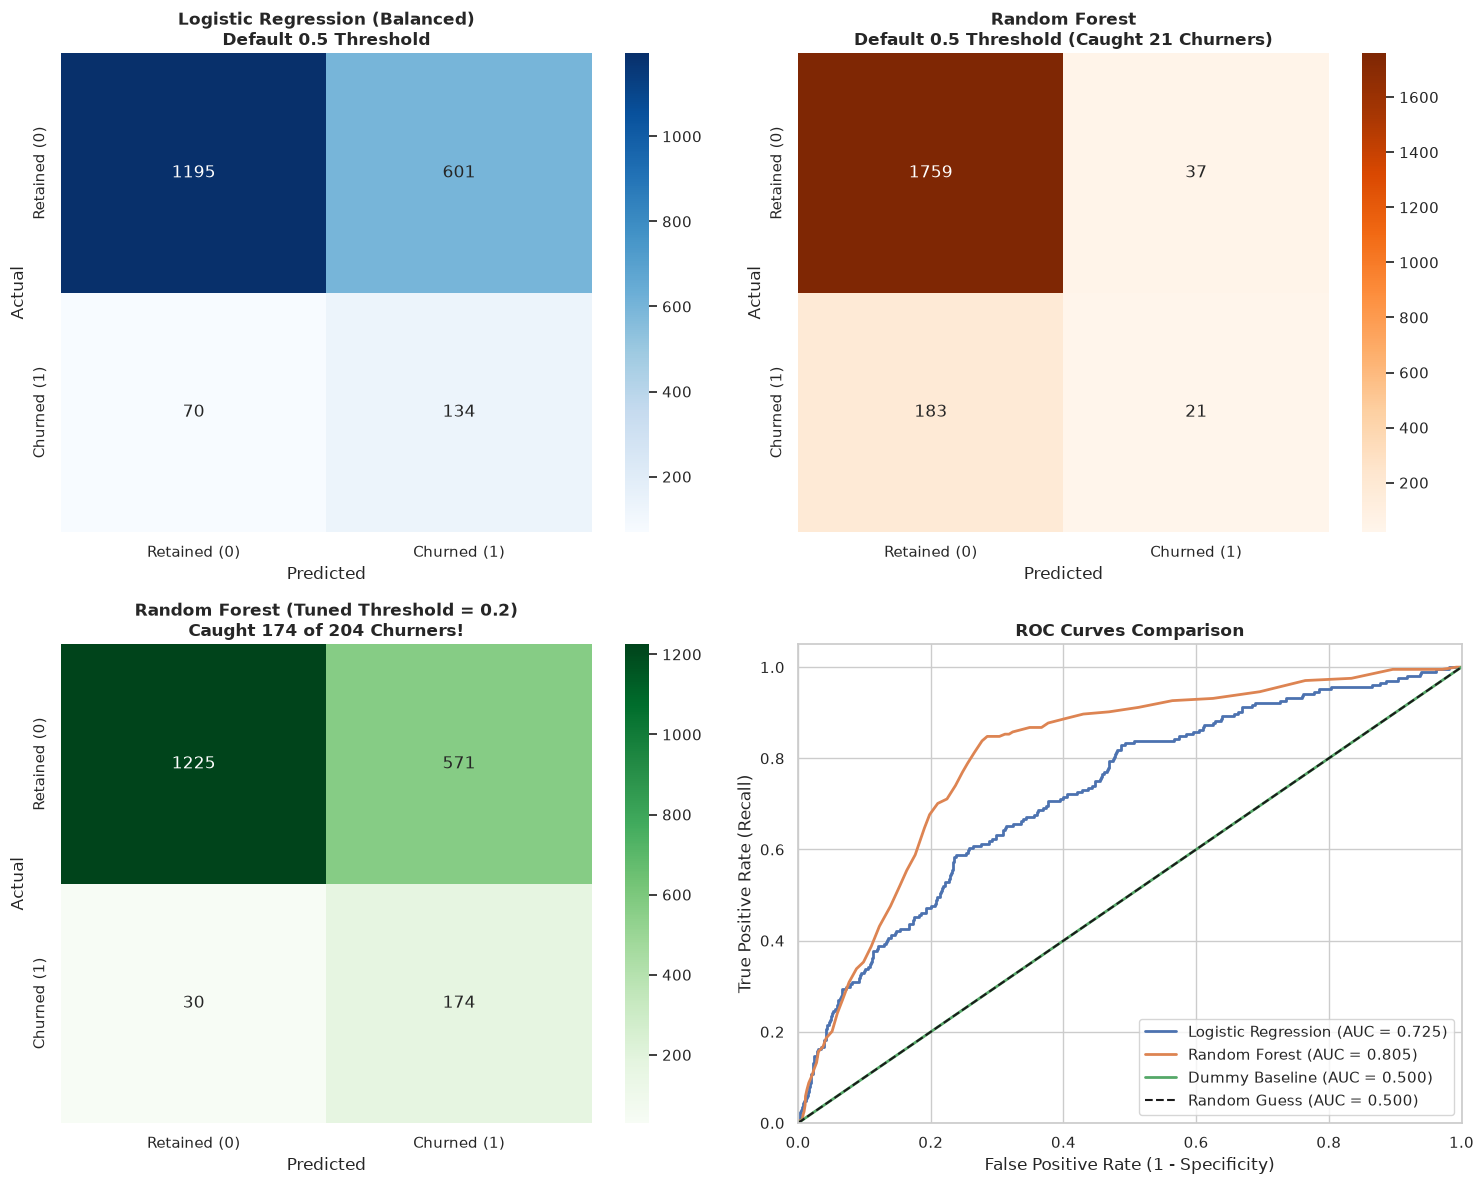

--- Impact of Tuning Random Forest Threshold to 0.2 ---
Default 0.50 Threshold: Caught 21 churners (10.3% Recall)
Tuned   0.20 Threshold: Caught 174 churners (85.3% Recall)


In [17]:
# --- STEP 6.1: VISUAL EVALUATION & THRESHOLD TUNING ---

from sklearn.metrics import confusion_matrix, roc_curve, auc

# 1. Optimal Decision Threshold for Random Forest
# In a ~10% churn dataset, a customer with >= 20% churn probability is at high risk!
optimal_threshold = 0.20
y_pred_rf_tuned = (y_proba_rf >= optimal_threshold).astype(int)

# 2. Setup 2x2 visual dashboard
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Subplot A: Logistic Regression Confusion Matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', ax=axes[0, 0],
            xticklabels=['Retained (0)', 'Churned (1)'],
            yticklabels=['Retained (0)', 'Churned (1)'])
axes[0, 0].set_title("Logistic Regression (Balanced)\nDefault 0.5 Threshold", fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel("Predicted")
axes[0, 0].set_ylabel("Actual")

# Subplot B: Random Forest (Default 0.5 Threshold)
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Oranges', ax=axes[0, 1],
            xticklabels=['Retained (0)', 'Churned (1)'],
            yticklabels=['Retained (0)', 'Churned (1)'])
axes[0, 1].set_title(f"Random Forest\nDefault 0.5 Threshold (Caught {cm_rf[1,1]} Churners)", fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel("Predicted")
axes[0, 1].set_ylabel("Actual")

# Subplot C: Random Forest (Tuned 0.20 Threshold)
cm_rf_tuned = confusion_matrix(y_test, y_pred_rf_tuned)
sns.heatmap(cm_rf_tuned, annot=True, fmt='d', cmap='Greens', ax=axes[1, 0],
            xticklabels=['Retained (0)', 'Churned (1)'],
            yticklabels=['Retained (0)', 'Churned (1)'])
axes[1, 0].set_title(f"Random Forest (Tuned Threshold = {optimal_threshold})\nCaught {cm_rf_tuned[1,1]} of {cm_rf_tuned[1,0]+cm_rf_tuned[1,1]} Churners!", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("Predicted")
axes[1, 0].set_ylabel("Actual")

# Subplot D: ROC Curves Comparison
for name, proba in [('Logistic Regression', y_proba_lr), ('Random Forest', y_proba_rf), ('Dummy Baseline', y_proba_dummy)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    roc_score = auc(fpr, tpr)
    axes[1, 1].plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_score:.3f})")

axes[1, 1].plot([0, 1], [0, 1], 'k--', lw=1.5, label="Random Guess (AUC = 0.500)")
axes[1, 1].set_xlim([0.0, 1.0])
axes[1, 1].set_ylim([0.0, 1.05])
axes[1, 1].set_xlabel("False Positive Rate (1 - Specificity)")
axes[1, 1].set_ylabel("True Positive Rate (Recall)")
axes[1, 1].set_title("ROC Curves Comparison", fontsize=12, fontweight='bold')
axes[1, 1].legend(loc="lower right")

plt.tight_layout()
plt.show()

# Print summary of the threshold impact
print(f"--- Impact of Tuning Random Forest Threshold to {optimal_threshold} ---")
print(f"Default 0.50 Threshold: Caught {cm_rf[1,1]} churners ({cm_rf[1,1]/204*100:.1f}% Recall)")
print(f"Tuned   0.20 Threshold: Caught {cm_rf_tuned[1,1]} churners ({cm_rf_tuned[1,1]/204*100:.1f}% Recall)")

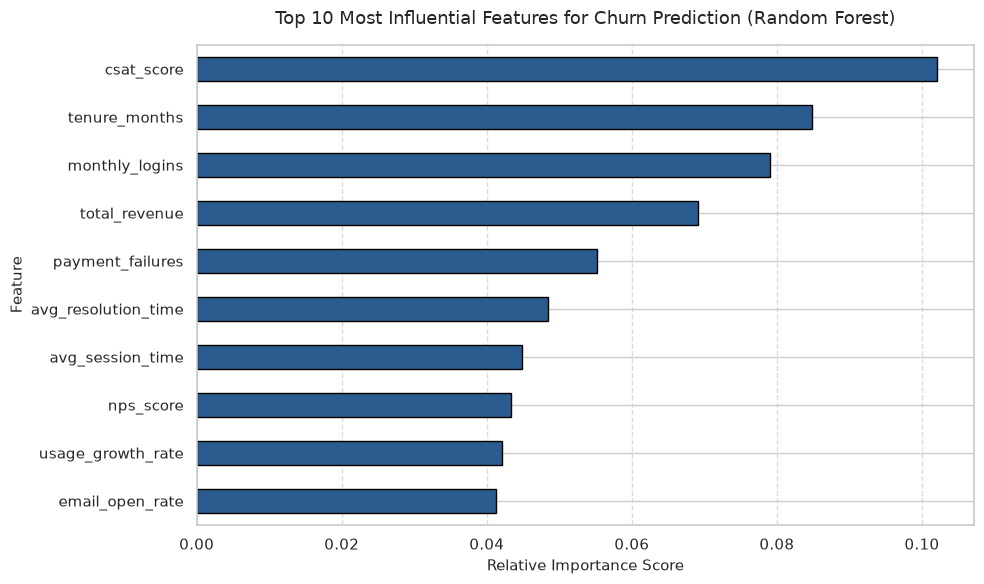

In [18]:
# --- STEP 6.2: FEATURE IMPORTANCES & BUSINESS DRIVERS ---

# Extract top 10 most influential features from Random Forest
feature_importances = pd.Series(rf.feature_importances_, index=X_train.columns)
top_10_features = feature_importances.sort_values(ascending=True).tail(10)

plt.figure(figsize=(10, 6))
top_10_features.plot(kind='barh', color='#2b5c8f', edgecolor='black')
plt.title("Top 10 Most Influential Features for Churn Prediction (Random Forest)", fontsize=13, pad=15)
plt.xlabel("Relative Importance Score", fontsize=11)
plt.ylabel("Feature", fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()